# S7 · Error variance without a truth assumption

Every stream is a noisy view of the same canopy — the ground included. Validation that treats plot measurements as truth assigns all disagreement to the satellite. Triple collocation estimates each system's error variance without nominating a reference.

**No novelty is claimed.** The 2026-08-08 literature audit found TC already applied to LAI and FAPAR, and both extensions the program proposed already published — Correlated Triple Collocation and Extended Quadruple Collocation for error-correlated datasets, and representativeness error as a standard additional term. The method is applied and cited, not reinvented.

What survives is the deliverable: **a per-observation uncertainty column on `hf365_v2_candidate`**, which is what CEOS LPV Stage 3 asks for.

Rebuild: `s7.results.run('evi2')`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from s7 import collocate, tc

BLUE, ORANGE, AQUA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#c9c8c3'
INK, INK2, SURF = '#0b0b0b', '#52514e', '#fcfcfb'
mpl.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'text.color': INK,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.edgecolor': GREY, 'font.size': 10})
def bare(ax):
    for s in ('top','right'): ax.spines[s].set_visible(False)

O = collocate.OUT
R    = json.loads((O/'results_summary.json').read_text())
t    = pd.read_csv(O/'triplet_evi2.csv', parse_dates=['ground_date'])
lin  = pd.read_csv(O/'linearity.csv')
sens = pd.read_csv(O/'sensitivity_correlated_errors.csv')
strat= pd.read_csv(O/'tc_by_stratum.csv')
print(json.dumps(R['collocation'])); print(json.dumps(R['effective_n']))

{"measure": "evi2", "n_triplets": 1800, "n_plots": 33, "n_ground_dates": 59, "n_modis_cells": 5, "window": ["2015-05-28", "2020-12-03"], "hls_tol_days": 4, "modis_tol_days": 4}
{"n_rows": 1800, "n_blocks": 279, "n_ground_dates": 59, "n_modis_cells": 5, "note": "rows within a (date, MODIS cell) block share one MODIS value; n_blocks is the honest sample size for anything MODIS-driven"}


## The triplet

Three supports on the same canopy: ground PAI over 314 m², HLS EVI2 over 900 m², MODIS LAI over ~215,000 m². Ground visits are the scarce term, so each anchors a triplet and the satellites are matched to it within ±4 days.

**Rows are not independent.** Five MODIS cells serve 33 plots, so every plot in a cell shares one MODIS value on a date. The honest sample size is the number of (date, cell) blocks, not rows — and everything below bootstraps on blocks.

In [2]:
print(t[['pai','hls','modis_lai']].corr().round(3).to_string())
print()
print('rows %d  ->  independent blocks %d' % (R['effective_n']['n_rows'], R['effective_n']['n_blocks']))

             pai    hls  modis_lai
pai        1.000  0.834      0.708
hls        0.834  1.000      0.838
modis_lai  0.708  0.838      1.000

rows 1800  ->  independent blocks 279


## Check the model before trusting the estimator

TC's model is linear. NDVI saturates against LAI, and a saturating relationship does not add noise — it breaks the estimator and returns model error dressed as measurement error.

This is why the product uses **EVI2**: adding a quadratic term to `pai ~ hls` reduces residual sum of squares by 0.0005 % (p = 0.93). On NDVI the same test cuts 14.1 % for ground and 22.9 % for MODIS.

In [3]:
print('EVI2 triplet:'); print(lin.round(4).to_string(index=False))
tn = pd.read_csv(O/'triplet_ndvi.csv', parse_dates=['ground_date'])
print('\nNDVI triplet — for contrast:')
print(tc.linearity(tn).round(4).to_string(index=False))

EVI2 triplet:
           pair    n  pearson  spearman  spearman_minus_pearson  quadratic_F  quadratic_p  curvature_reduces_ss_pct
      pai ~ hls 1800   0.8343    0.8384                  0.0041       0.0084       0.9269                    0.0005
pai ~ modis_lai 1800   0.7085    0.6958                 -0.0127      15.1247       0.0001                    0.8346
hls ~ modis_lai 1800   0.8380    0.8133                 -0.0247       3.6990       0.0546                    0.2054

NDVI triplet — for contrast:
           pair    n  pearson  spearman  spearman_minus_pearson  quadratic_F  quadratic_p  curvature_reduces_ss_pct
      pai ~ hls 1800   0.8860    0.8751                 -0.0109     295.3199       0.0000                   14.1145
pai ~ modis_lai 1800   0.7085    0.6958                 -0.0127      15.1247       0.0001                    0.8346
hls ~ modis_lai 1800   0.7706    0.7410                 -0.0295     534.7604       0.0000                   22.9338


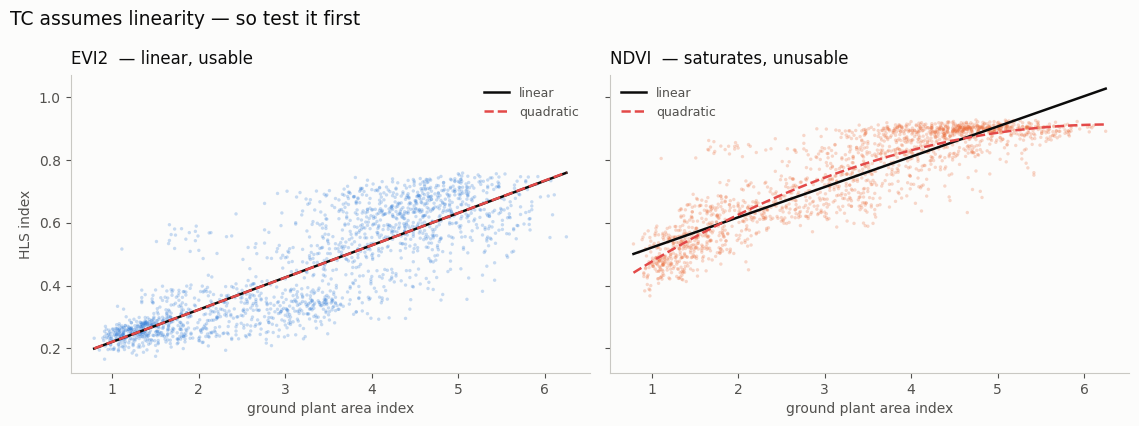

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.4,4.3), sharey=True)
for ax, d, lab, c in [(axes[0], t, 'EVI2  — linear, usable', BLUE),
                      (axes[1], tn, 'NDVI  — saturates, unusable', ORANGE)]:
    ax.scatter(d.pai, d.hls, s=6, alpha=.25, color=c, edgecolors='none')
    x = np.linspace(d.pai.min(), d.pai.max(), 100)
    b1 = np.polyfit(d.pai, d.hls, 1); b2 = np.polyfit(d.pai, d.hls, 2)
    ax.plot(x, np.polyval(b1, x), color=INK, lw=1.8, label='linear')
    ax.plot(x, np.polyval(b2, x), color=RED, lw=1.8, ls='--', label='quadratic')
    ax.set_xlabel('ground plant area index'); ax.set_title(lab, loc='left', fontsize=12, color=INK, pad=8)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK2); bare(ax)
axes[0].set_ylabel('HLS index')
fig.suptitle('TC assumes linearity — so test it first', x=0.005, ha='left', fontsize=13.5, color=INK)
plt.tight_layout(); plt.show()

## Result · error variance of each stream

Each in its own units, with 95 % intervals from a bootstrap over (date, cell) blocks. `rho2` is Extended TC's correlation with the unknown truth — a skill score that needs no reference dataset.

In [5]:
cl, ci = R['classical'], R['bootstrap_95ci']
units = {'ground':'PAI', 'hls':'EVI2', 'modis':'LAI'}
print(f"{'stream':8s} {'sd(error)':>10s} {'95% CI':>20s} {'rho2 truth':>11s} {'% of variance that is error':>29s}")
for n in tc.NAMES:
    print(f"{n:8s} {cl['sd_err_'+n]:10.4f} {str([round(v,4) for v in ci[n]]):>20s}"
          f" {cl['rho2_truth_'+n]:11.3f} {100*cl['frac_var_error_'+n]:28.1f}   ({units[n]})")
print()
print('Row-resampling instead of block-resampling would give intervals ~2.2x too narrow.')

stream    sd(error)               95% CI  rho2 truth   % of variance that is error
ground       0.7588     [0.6866, 0.8166]       0.705                         29.5   (PAI)
hls          0.0197     [0.0062, 0.0397]       0.987                          1.3   (EVI2)
modis        1.1435     [0.9642, 1.2967]       0.712                         28.8   (LAI)

Row-resampling instead of block-resampling would give intervals ~2.2x too narrow.


## The assumption that is known to fail here

TC assumes errors are independent across systems. HLS and MODIS share optical physics, similar bands and comparable atmospheric correction, so theirs are correlated by construction. Classical TC reads shared satellite *error* as shared *signal* — which flatters both satellites and penalises the ground.

Rather than propose a method for that (CTC and EQC already exist), the sweep below shows the direction and size of the effect. It also yields a bound the data supplies on its own: past ~30 % assumed error covariance, the ground's correlation with truth exceeds 1, which cannot happen. **The true error correlation is below that.**

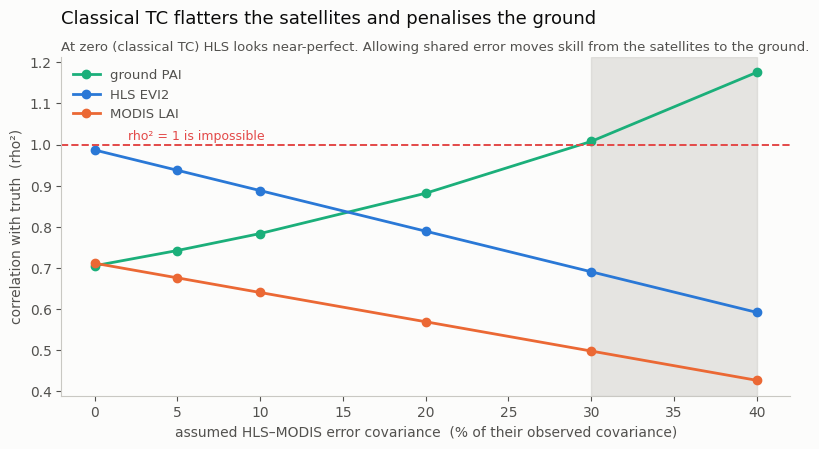

In [6]:
fig, ax = plt.subplots(figsize=(9.4,4.4))
for n, c, lab in [('ground', AQUA, 'ground PAI'), ('hls', BLUE, 'HLS EVI2'), ('modis', ORANGE, 'MODIS LAI')]:
    ax.plot(100*sens.assumed_err_corr_frac, sens['rho2_truth_'+n], 'o-', color=c, lw=2, ms=6, label=lab)
ax.axhline(1.0, color=RED, lw=1.4, ls='--')
ax.annotate('rho² = 1 is impossible', xy=(2, 1.012), fontsize=9, color=RED)
b = 100*R['correlated_error_bound']['impossible_at_frac']
ax.axvspan(b, 100*sens.assumed_err_corr_frac.max(), color=GREY, alpha=.45, zorder=0)
ax.annotate('excluded by the data', xy=(b+1.5, 0.22), fontsize=9.5, color=INK2)
ax.set_xlabel('assumed HLS–MODIS error covariance  (% of their observed covariance)')
ax.set_ylabel('correlation with truth  (rho²)')
ax.set_title('Classical TC flatters the satellites and penalises the ground',
             loc='left', fontsize=13, color=INK, pad=24)
ax.annotate('At zero (classical TC) HLS looks near-perfect. Allowing shared error moves skill from the satellites to the ground.',
            xy=(0,1.02), xycoords='axes fraction', fontsize=9.5, color=INK2)
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK2); bare(ax); plt.show()

## Why the uncertainty cannot be made conditional on season

A per-observation uncertainty ought to vary with conditions. It cannot here, and the reason is structural rather than a shortage of data.

TC needs the latent quantity to **vary**. The growing season holds only 18 % of the record's variance in plant area index, and the shoulder seasons change fast enough that a ±4 day match is itself a source of disagreement. Every within-season stratum returns a correlation with truth outside (0, 1), or collapses toward zero — the estimator breaking, not a system being unusually good or bad.

Per-**product** strata do survive, because each spans the full seasonal cycle. So the shipped column is product-specific and honest about its grain.

In [7]:
print(strat[['stratum','n_blocks','signal_var_frac','trusted','rho2_truth_hls','why_not']]
        .round(3).fillna('').to_string(index=False))

      stratum  n_blocks  signal_var_frac  trusted  rho2_truth_hls                                         why_not
      growing        80            0.181    False           0.777 retains only 18 % of the pooled signal variance
          off       199            0.760    False           1.064                              rho2 outside (0,1)
          L30       173            1.026     True           0.993                                                
          S30       109            0.939     True           0.983                                                
growing / L30        44            0.186    False           0.090 retains only 19 % of the pooled signal variance
growing / S30        37            0.169    False          -0.059                              rho2 outside (0,1)
    off / L30       129            0.832    False           1.043                              rho2 outside (0,1)
    off / S30        72            0.632    False           1.180                       

## The deliverable

`hf365_v2_candidate.csv` now carries `evi2_sd_tc`, `evi2_sd_tc_ci_lo/hi` and `evi2_sd_tc_source` on every usable observation.

An archived product shipping characterised uncertainty is more than a reprocessing — it is the CEOS LPV Stage 3 requirement, which asks for characterised uncertainty rather than better estimates.

In [8]:
from s1 import io as sio
v2 = pd.read_csv(sio.OUT/'hf365_v2_candidate.csv')
u = v2[v2.single_usable]
print(u.groupby('product')[['evi2_sd_tc']].agg(n=('evi2_sd_tc','size'), sd=('evi2_sd_tc','first')).round(5).to_string())
print()
for p in ('L30','S30'):
    d = u[u['product']==p]
    print(f"  {p}: sd {d.evi2_sd_tc.iloc[0]:.4f} EVI2 = {100*d.evi2_sd_tc.iloc[0]/d.evi2_single.median():.1f} % of a typical value")
print()
print(u[['date','plot','product','evi2_single','evi2_sd_tc','evi2_sd_tc_ci_lo','evi2_sd_tc_ci_hi','evi2_sd_tc_source']].head(4).to_string(index=False))

            n       sd
product               
L30      7590  0.01451
S30      6156  0.02265

  L30: sd 0.0145 EVI2 = 3.1 % of a typical value
  S30: sd 0.0227 EVI2 = 4.3 % of a typical value

      date plot product  evi2_single  evi2_sd_tc  evi2_sd_tc_ci_lo  evi2_sd_tc_ci_hi evi2_sd_tc_source
2015-05-08   A1     L30     0.321773     0.01451          0.006204          0.039692           product
2015-05-08   A2     L30     0.320500     0.01451          0.006204          0.039692           product
2015-05-08   A3     L30     0.317287     0.01451          0.006204          0.039692           product
2015-05-08   A4     L30     0.364535     0.01451          0.006204          0.039692           product


## What to carry forward, and what not to claim

**Sentinel-2 EVI2 carries ~1.6× the error of Landsat EVI2** at these plots (0.0227 vs 0.0145). Anything pooling the two streams without weighting is treating unequal observations as equal.

**The ground is not truth.** Its error variance is ~29 % of its total variance — comparable to MODIS. Validation that assigns all disagreement to the satellite is mis-attributing roughly a third of it.

**Do not claim** that TC on vegetation indices is new, that testing the independence assumption is new, or that representativeness-error decomposition is new. All three are published; see the kill-test record. The contribution is the column, not the method.

**Limitations to state plainly.** The uncertainty is a whole-record, per-product estimate — it is not conditional on season, and this data cannot make it so. MODIS coverage ends 2020-12-26, so the estimate rests on 2015–2020 and is applied to observations through 2026. And 5 MODIS cells over 33 plots means the MODIS term is far less independent than the row count suggests.